The banking churn prediction dataset (uploaded in the same folder) contains different attributes of the customers of the bank and whether they have churned or not. Churning means closing the relationship with the bank. Following are the descriptions of the columns in the dataset.

customer_id: Unique identifier for each customer.
vintage: The duration of the customer's relationship with the company.
age: Age of the customer.
gender: Gender of the customer.
dependents: Number of dependents the customer has.
occupation: The occupation of the customer.
city: City in which the customer is located.
customer_nw_category: Net worth category of the customer.
branch_code: Code identifying the branch associated with the customer.
current_balance: Current balance in the customer's account.
previous_month_end_balance: Account balance at the end of the previous month.
average_monthly_balance_prevQ: Average monthly balance in the previous quarter.
average_monthly_balance_prevQ2: Average monthly balance in the second previous quarter.
current_month_credit: Credit amount in the current month.
previous_month_credit: Credit amount in the previous month.
current_month_debit: Debit amount in the current month.
previous_month_debit: Debit amount in the previous month.
current_month_balance: Account balance in the current month.
previous_month_balance: Account balance in the previous month.
churn: The target variable indicating whether the customer has churned (1 for churned, 0 for not churned).
last_transaction: Timestamp of the customer's last transaction.

In [2]:
import pandas as pd
bank_churn = pd.read_csv('Banking_churn_prediction.csv')
bank_churn.head


<bound method NDFrame.head of        customer_id  vintage  age  gender  dependents     occupation    city  \
0                1     2101   66    Male         0.0  self_employed   187.0   
1                2     2348   35    Male         0.0  self_employed     NaN   
2                4     2194   31    Male         0.0       salaried   146.0   
3                5     2329   90     NaN         NaN  self_employed  1020.0   
4                6     1579   42    Male         2.0  self_employed  1494.0   
...            ...      ...  ...     ...         ...            ...     ...   
28377        30297     2325   10  Female         0.0        student  1020.0   
28378        30298     1537   34  Female         0.0  self_employed  1046.0   
28379        30299     2376   47    Male         0.0       salaried  1096.0   
28380        30300     1745   50    Male         3.0  self_employed  1219.0   
28381        30301     1175   18    Male         0.0        student  1232.0   

       customer_nw_ca

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
bank_churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 28382 entries, 0 to 28381
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   customer_id                     28382 non-null  int64  
 1   vintage                         28382 non-null  int64  
 2   age                             28382 non-null  int64  
 3   gender                          27857 non-null  str    
 4   dependents                      25919 non-null  float64
 5   occupation                      28302 non-null  str    
 6   city                            27579 non-null  float64
 7   customer_nw_category            28382 non-null  int64  
 8   branch_code                     28382 non-null  int64  
 9   current_balance                 28382 non-null  float64
 10  previous_month_end_balance      28382 non-null  float64
 11  average_monthly_balance_prevQ   28382 non-null  float64
 12  average_monthly_balance_prevQ2  28382 non-n

In [10]:
bank_churn['gender'].isnull().sum()

np.int64(525)

In [12]:
bank_churn['occupation'].value_counts()

occupation
self_employed    17476
salaried          6704
student           2058
retired           2024
company             40
Name: count, dtype: int64

In [13]:
def describe_categorical(column):
    '''Print a frequency distribution table and plot a bar chart + pie chart.'''
    counts = bank_churn[column].value_counts()
    pct = (counts / counts.sum() * 100).round(2)
    freq_table = pd.DataFrame({"Count": counts, "Percentage": pct})
    display(freq_table)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    counts.plot(kind="bar", ax=axes[0], color="#4C72B0")
    axes[0].set_title(f"Bar Chart: {column}")
    axes[0].set_ylabel("Count")

    axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90)
    axes[1].set_title(f"Pie Chart: {column}")
    plt.tight_layout()
    plt.show()

,Count,Percentage
occupation,,
self_employed,17476,61.75
salaried,6704,23.69
student,2058,7.27
retired,2024,7.15
company,40,0.14


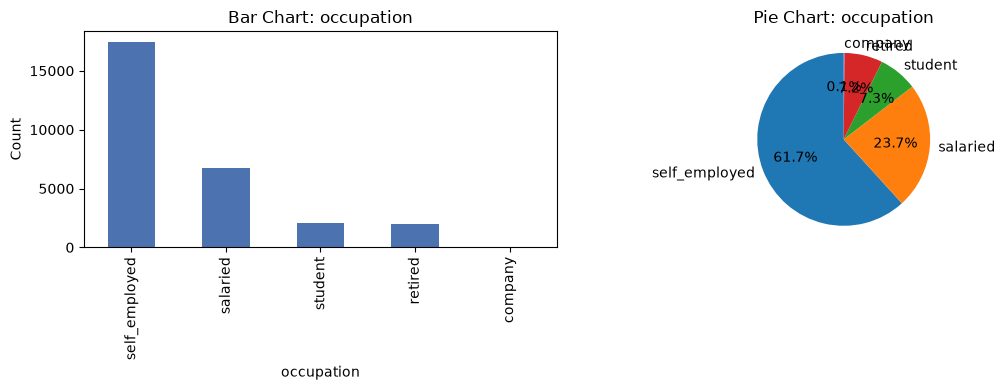

In [14]:
describe_categorical('occupation')

,Count,Percentage
gender,,
Male,16548,59.4
Female,11309,40.6


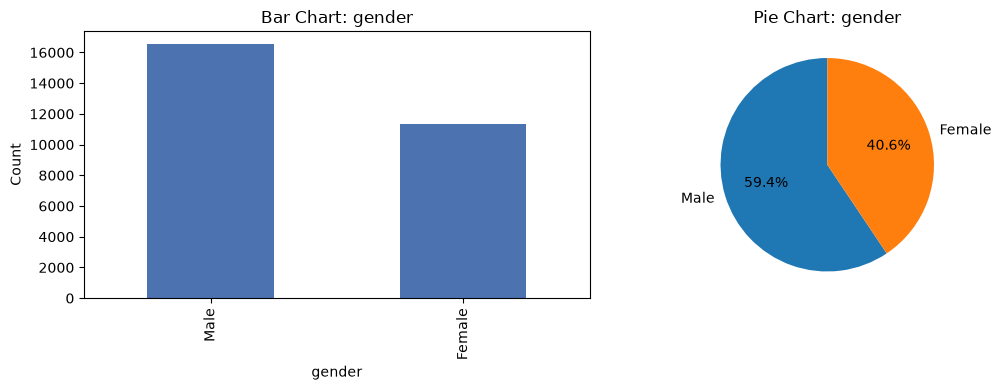

In [16]:
describe_categorical('gender')

,Count,Percentage
city,,
1020.0,3479,12.61
1096.0,2016,7.31
409.0,1334,4.84
146.0,1291,4.68
834.0,1138,4.13
...,...,...
343.0,1,0.00
1028.0,1,0.00
556.0,1,0.00


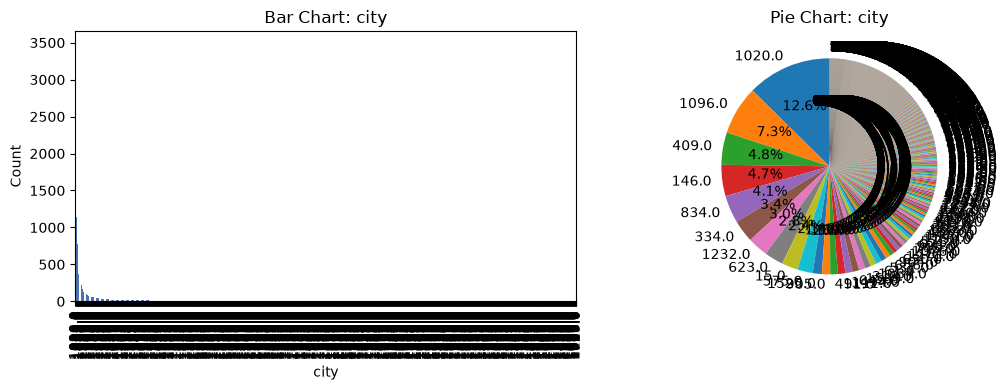

In [21]:
describe_categorical('city')

In [18]:
def describe_quantitative(column):
    '''Print central tendency + dispersion stats and plot a histogram + boxplot.'''
    data = bank_churn[column]

    mean_, median_ = data.mean(), data.median()
    mode_ = data.mode()[0]
    min_, max_ = data.min(), data.max()
    range_ = max_ - min_
    var_, std_ = data.var(), data.std()
    q1, q3 = data.quantile(0.25), data.quantile(0.75)
    iqr = q3 - q1

    summary = pd.Series(
        {
            "Mean": mean_, "Median": median_, "Mode": mode_,
            "Min": min_, "Q1": q1, "Q3": q3, "Max": max_,
            "Range": range_, "Variance": var_, "Std Dev": std_, "IQR": iqr,
        }
    ).round(2)
    display(summary)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    data.plot(kind="hist", bins=30, ax=axes[0], color="#58C972")
    axes[0].axvline(mean_, color="red", linestyle="--", label="Mean")
    axes[0].axvline(median_, color="black", linestyle="--", label="Median")
    axes[0].set_title(f"Histogram: {column}")
    axes[0].legend()

    data.plot(kind="box", ax=axes[1], vert=False, color="#3218B1")
    axes[1].set_title(f"Boxplot: {column}")
    plt.tight_layout()
    plt.show()

Mean         48.21
Median       46.00
Mode         90.00
Min           1.00
Q1           36.00
Q3           60.00
Max          90.00
Range        89.00
Variance    317.10
Std Dev      17.81
IQR          24.00
dtype: float64

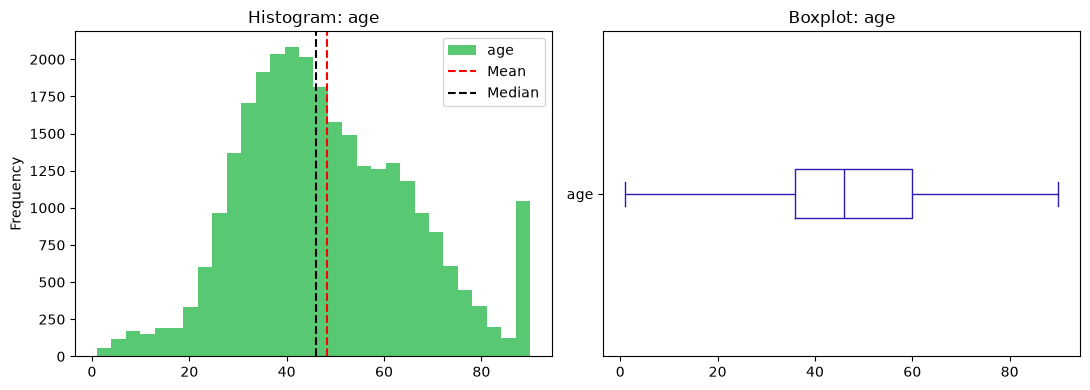

In [19]:
describe_quantitative('age')

Mean        2.23
Median      2.00
Mode        2.00
Min         1.00
Q1          2.00
Q3          3.00
Max         3.00
Range       2.00
Variance    0.44
Std Dev     0.66
IQR         1.00
dtype: float64

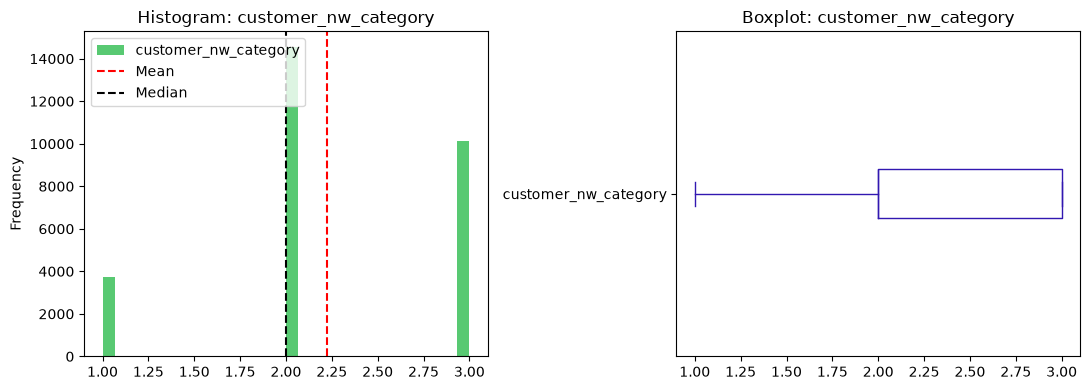

In [23]:
describe_quantitative('customer_nw_category')

Mean         0.35
Median       0.00
Mode         0.00
Min          0.00
Q1           0.00
Q3           0.00
Max         52.00
Range       52.00
Variance     1.00
Std Dev      1.00
IQR          0.00
dtype: float64

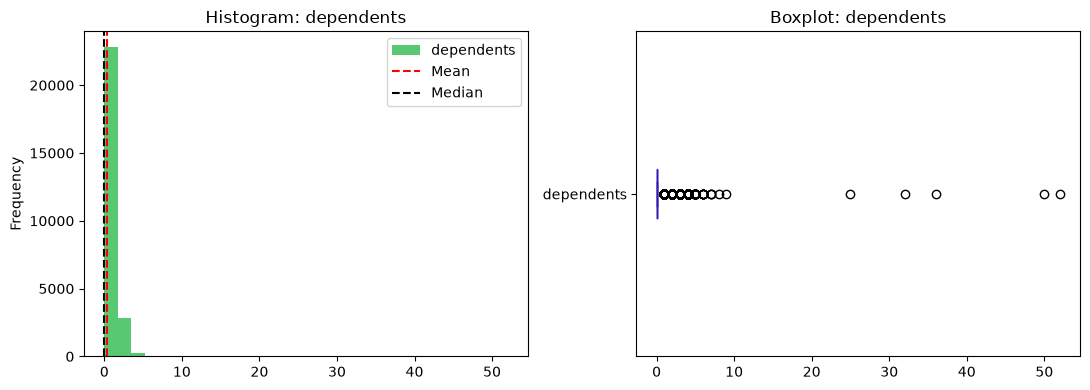

In [25]:
describe_quantitative('dependents')

In [27]:
def tukey_outliers(column):
    data = bank_churn[column]
    q1, q3 = data.quantile(0.25), data.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = data[(data < lower) | (data > upper)]
    print(f"{column}: lower bound = {lower:.2f}, upper bound = {upper:.2f}")
    print(f"Number of outliers: {len(outliers)} out of {len(data)} ({len(outliers)/len(data)*100:.2f}%)")
    return outliers

bank_churns = tukey_outliers('churn')
bank_churns

churn: lower bound = 0.00, upper bound = 0.00
Number of outliers: 5260 out of 28382 (18.53%)


3        1
4        1
12       1
14       1
16       1
        ..
28368    1
28372    1
28374    1
28379    1
28381    1
Name: churn, Length: 5260, dtype: int64

In [28]:
two_way = pd.crosstab(bank_churn["occupation"], bank_churn["customer_nw_category"])
two_way["Total"] = two_way.sum(axis=1)
two_way

customer_nw_category,1,2,3,Total
occupation,,,,
company,6,17,17,40
retired,232,1047,745,2024
salaried,800,3270,2634,6704
self_employed,2330,9091,6055,17476
student,338,1099,621,2058


In [29]:
row_pct = pd.crosstab(bank_churn["occupation"], bank_churn["customer_nw_category"], normalize="index") * 100
row_pct.round(1)

customer_nw_category,1,2,3
occupation,,,
company,15.0,42.5,42.5
retired,11.5,51.7,36.8
salaried,11.9,48.8,39.3
self_employed,13.3,52.0,34.6
student,16.4,53.4,30.2
